In [1]:
import turicreate as tc
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

import json
import sys
import os
import random
import time

from sklearn.metrics.pairwise import pairwise_distances
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.preprocessing import normalize

from copy import copy
from collections import defaultdict 
from itertools import combinations

In [2]:
json_data = tc.SFrame.read_json("news_dataset.json")
json_data 

Parsing JSON records from /home/enderu/Downloads/ML-clustering/news_dataset.json

Successfully parsed 184539 elements from the JSON file /home/enderu/Downloads/ML-clustering/news_dataset.json

author,content,crawled_at,id,picture_count,processed
,"Chiều 31/7, Công an tỉnhThừa Thiên - Huế đã có ...",2022-08-0109:09:22.817308 ...,218270,3,0
(Nguồn: Sina),"Gần đây, Thứ trưởng BộPhát triển Kỹ thuật số, ...",2022-08-0109:09:21.181469 ...,218269,1,0
Hồ Sỹ Anh,Kết quả thi tốt nghiệpTHPT năm 2022 cho thấy ...,2022-08-0109:09:15.311901 ...,218268,3,0
Ngọc Ánh,Thống đốc Kentucky AndyBeshear hôm 31/7 cho hay ...,2022-08-0109:09:02.211498 ...,218267,1,0
HẢI YẾN - MINH LÝ,Vụ tai nạn giao thôngliên hoàn trên phố đi bộ ...,2022-08-0109:09:01.601170 ...,218266,12,0
,"Chia sẻ trên Twitter, thịtrưởng Hanover Belit ...",2022-08-0109:09:01.320653 ...,218265,2,0
,"""Em vỡ òa trong hạnh phúckhi được xướng tên ở ...",2022-08-0109:08:57.167808 ...,218264,8,0
Hoàng Yến/VOV.VN,,2022-08-0109:08:51.092437 ...,218263,1,0
T.G,Soi kèo nhà cái Liverpoolvs Strasbourg. Nhận đ ...,2022-08-0109:08:47.355309 ...,218262,3,0
Đỗ Trung,Siêu sao Bồ Đào Nha đượcHLV Erik ten Hag bố trí ...,2022-08-0109:08:42.496092 ...,218261,1,0


In [3]:
clean_data = json_data.dropna()
sample_fraction = 3000 / len(clean_data)

dataset1 = clean_data.sample(sample_fraction, seed=0)
dataset1 = dataset1[dataset1['content'].apply(lambda x: x != None and str(x).strip() != '')]
dataset1 = dataset1[:2000]

In [4]:
[dataset1]

[Columns:
 	author	str
 	content	str
 	crawled_at	str
 	id	int
 	picture_count	int
 	processed	int
 	source	str
 	title	str
 	topic	str
 	url	str
 
 Rows: 2000
 
 Data:
 +-------------------------------+-------------------------------+
 |             author            |            content            |
 +-------------------------------+-------------------------------+
 |     Bài và ảnh: Thanh Tuấn    | Ghi nhận của phóng viên tạ... |
 |                               | Theo Thời báo Hoàn Cầu ngà... |
 |             AN AN             | Dự báo thời tiết hôm nay 1... |
 | Theo Ngọc Lâm (Tạp chí Du ... |  PSG đối đầu với Nantes tr... |
 |           Gia Khiêm           | Đầu tháng 7 vừa qua, người... |
 |  DOÃN HẰNG (THEO STYLECRAZE)  | Chữa lành vết thương Dầu m... |
 | Theo Trịnh Xuân nguyên (Th... | Chuyên gia dinh dưỡng Vidh... |
 | Quỳnh Anh-Chủ nhật, ngày 3... | Tại cơ sở 2 Bệnh viện Bệnh... |
 |         Lê Anh/VOV.VN         | Giao lộ thời gian số 3 với... |
 |            Loan Chi     

In [5]:
dataset1['word_count'] = tc.text_analytics.count_words(dataset1['content'])
dataset1['tfidf'] = tc.text_analytics.tf_idf(dataset1['content'])

In [6]:
topics_of_choice = ['Pháp luật', 'Giáo dục', 'Thế giới', 'Giải trí']

dataset2 = clean_data[clean_data['topic'].apply(lambda x: x in topics_of_choice)]
sample_fraction = 3000/ len(dataset2)
dataset2 = dataset2.sample(sample_fraction)
dataset2 = dataset2[dataset2['content'].apply(lambda x: x != None and str(x).strip() != '')]
dataset2 = dataset2[:2000]
[dataset2]

[Columns:
 	author	str
 	content	str
 	crawled_at	str
 	id	int
 	picture_count	int
 	processed	int
 	source	str
 	title	str
 	topic	str
 	url	str
 
 Rows: 2000
 
 Data:
 +-------------------------------+-------------------------------+
 |             author            |            content            |
 +-------------------------------+-------------------------------+
 |                               | Chia sẻ trên Twitter, thị ... |
 |          Ngô Minh Trí         | Thiếu tướng Christopher Mc... |
 |           Bình Giang          | Ông Oleksiy Vadatursky, ng... |
 |            Vi Trân            | Lãnh đạo Cơ quan Hàng khôn... |
 |                               | Tối 31/7, Đoàn Thu Thủy đư... |
 |           Phạm Công           | Chiều 31/7, ở Thừa Thiên H... |
 |           Thạch Anh           | Không chỉ sở hữu nhan sắc ... |
 |          Hoàng Thuận          | Ngày 31/7, Công an quận Bì... |
 | Phương Đăng (theo Barrons/... | Theo Barrons, Sergiy Bratc... |
 | Minh Nhật (theo Times Of

In [7]:
dataset2['word_count'] = tc.text_analytics.count_words(dataset2['content'])
dataset2['tfidf'] = tc.text_analytics.tf_idf(dataset2['content'])

In [8]:
def sframe_to_scipy_kmean(x, column_name):
    assert type(x[column_name][0]) == dict, \
        'Datatype not dict!'
    
    x = x.add_row_number('new_id')

    x = x.stack(column_name, ['feature', 'value'])

    unique_words = sorted(x['feature'].unique())
    mapping = {word:i for i, word in enumerate(unique_words)}
    x['feature_id'] = x['feature'].apply(lambda x: mapping[x])

    row_id = np.array(x['new_id'])
    col_id = np.array(x['feature_id'])
    data = np.array(x['value'])
    
    width = x['new_id'].max() + 1
    height = x['feature_id'].max() + 1
    
    mat = csr_matrix((data, (row_id, col_id)), shape=(width, height))
    return mat, mapping

In [9]:
def assign_clusters(data, centroids):
    distances_from_centroids = pairwise_distances(data, centroids, metric='euclidean')
    cluster_assignment = np.argmin(distances_from_centroids, axis=1)
    return cluster_assignment

In [10]:
def revise_centroids(data, k, cluster_assignment):
    new_centroids = []
    for i in range(k):
        member_data_points = data[cluster_assignment==i]
        centroid = member_data_points.mean(axis=0)
        centroid = centroid.A1
        new_centroids.append(centroid)
    new_centroids = np.array(new_centroids)
    
    return new_centroids

In [11]:
def compute_heterogeneity(data, k, centroids, cluster_assignment):
    heterogeneity = 0.0
    for i in range(k):
        member_data_points = data[cluster_assignment==i, :]
        
        if member_data_points.shape[0] > 0: 
            distances = pairwise_distances(member_data_points, [centroids[i]], metric='euclidean')
            squared_distances = distances**2
            heterogeneity += np.sum(squared_distances)
        
    return heterogeneity

In [12]:
def smart_initialize(data, k, seed=None):
    if seed is not None:
        np.random.seed(seed)
    centroids = np.zeros((k, data.shape[1]))

    idx = np.random.randint(data.shape[0])
    centroids[0] = data[idx,:].toarray()
    squared_distances = pairwise_distances(data, centroids[0:1], metric='euclidean').flatten()**2
    
    for i in range(1, k):
        idx = np.random.choice(data.shape[0], 1, p=squared_distances/sum(squared_distances))
        centroids[i] = data[idx,:].toarray()
       
        squared_distances = np.min(pairwise_distances(data, centroids[0:i+1], metric='euclidean')**2,axis=1)
    
    return centroids

In [13]:
def kmeans(data, k, initial_centroids, maxiter, record_heterogeneity=None, verbose=False):
    centroids = initial_centroids[:]
    prev_cluster_assignment = None
    
    for itr in range(maxiter):        
        if verbose:
            print(itr)

        cluster_assignment = assign_clusters(data, centroids)
        centroids = revise_centroids(data, k, cluster_assignment)        
        
        if prev_cluster_assignment is not None and \
          (prev_cluster_assignment==cluster_assignment).all():
            break
        
        if prev_cluster_assignment is not None:
            num_changed = np.sum(prev_cluster_assignment!=cluster_assignment)
            if verbose:
                print('    {0:5d} elements changed their cluster assignment.'.format(num_changed))   
        
        if record_heterogeneity is not None:
            score = compute_heterogeneity(data, k, centroids, cluster_assignment)
            record_heterogeneity.append(score)
        
        prev_cluster_assignment = cluster_assignment[:]
        
    return centroids, cluster_assignment

In [14]:
def get_initial_centroids(data, k, seed=None):
    if seed is not None: 
        np.random.seed(seed)
    n = data.shape[0] # number of data points
        
    # Pick K indices from range [0, N).
    rand_indices = np.random.randint(0, n, k)

    centroids = data[rand_indices,:].toarray()
    
    return centroids

In [15]:
def kmeans_multiple_runs(data, k, maxiter, num_runs, seed_list=None, verbose=False):
    heterogeneity = {}
    
    min_heterogeneity_achieved = float('inf')
    best_seed = None
    final_centroids = None
    final_cluster_assignment = None
    
    for i in range(num_runs):
        if seed_list is not None: 
            seed = seed_list[i]
            np.random.seed(seed)
        else: 
            seed = int(time.time())
            np.random.seed(seed)
        
        initial_centroids = smart_initialize(data, k, seed=seed)
    
        centroids, cluster_assignment = kmeans(data, k, initial_centroids, maxiter=400,
                                               record_heterogeneity=None, verbose=False)
        
        heterogeneity[seed] = compute_heterogeneity(data, k, centroids, cluster_assignment)
        
        if verbose:
            print('seed={0:06d}, heterogeneity={1:.5f}'.format(seed, heterogeneity[seed]))
            sys.stdout.flush()
        
        if heterogeneity[seed] < min_heterogeneity_achieved:
            min_heterogeneity_achieved = heterogeneity[seed]
            best_seed = seed
            final_centroids = centroids
            final_cluster_assignment = cluster_assignment
     
    return final_centroids, final_cluster_assignment

In [16]:
def get_similar_docs_kmean(query_doc_id, centroids, cluster_assignment):
    id_to_index = {doc['id']: i for i, doc in enumerate(dataset1)}
    query_doc_index = id_to_index[query_doc_id]
    cluster_idx = cluster_assignment[k][query_doc_index]
    same_centroid_indices = [i for i, cluster in enumerate(cluster_assignment[k]) if cluster == cluster_idx]
    same_centroid_doc_ids = [list(id_to_index.keys())[list(id_to_index.values()).index(i)] for i in same_centroid_indices]
    similar_docs_sf = tc.SFrame({'id': same_centroid_doc_ids})
    similar_docs_sf = similar_docs_sf[similar_docs_sf['id'] != query_doc_id]
    similar_docs_sf = similar_docs_sf.head(10).join(dataset1[['id', 'topic', 'title', 'content']], on='id')
    return similar_docs_sf

In [17]:
def visualize_document_clusters(dataset, tf_idf, centroids, cluster_assignment, k, map_word_to_index, display_content=True):
    map_index_to_word =  {v:k for k,v in map_word_to_index.items()}
    print('==========================================================')
    for c in range(k): 
        print('Cluster {0:d}    '.format(c)),

        idx = centroids[c].argsort()[::-1]
        for i in range(5): 
            print('{0:s}:{1:.3f}'.format(map_index_to_word[idx[i]], centroids[c][idx[i]])),
        print('')
        
        if display_content:
            distances = pairwise_distances(tf_idf, centroids[c].reshape(1, -1), metric='euclidean').flatten()
            distances[cluster_assignment!=c] = float('inf') 
            
            nearest_neighbors = distances.argsort()

            for i in range(8):
                text = ' '.join(dataset[nearest_neighbors[i]]['content'].split(None, 25)[0:25])
                print('\n* {0:50s} {1:.5f}\n  {2:s}\n  {3:s}'.format(dataset[nearest_neighbors[i]]['topic'],
                    distances[nearest_neighbors[i]], text[:90], text[90:180] if len(text) > 90 else ''))
        print('==========================================================')
    

In [18]:
tf_idf, map_index_to_word = sframe_to_scipy_kmean(dataset1, 'tfidf') #term frequency / inverse doc 
tf_idf = normalize(tf_idf)
centroids = {}
cluster_assignment = {}
heterogeneity_values = []
k_list = [3, 10, 100]
seed_list = [0]
for k in k_list:
    heterogeneity = []
    centroids[k], cluster_assignment[k] = kmeans_multiple_runs(tf_idf, k, maxiter=400,
                                                               num_runs=len(seed_list), seed_list=seed_list,
                                                               verbose=True)
    score = compute_heterogeneity(tf_idf, k, centroids[k], cluster_assignment[k])
    heterogeneity_values.append(score)

seed=000000, heterogeneity=1903.62529
seed=000000, heterogeneity=1834.10863
seed=000000, heterogeneity=1636.45003


In [26]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import itertools

def plotting_kmeans(k, tf_idf, centroids, cluster_assignment):
    pca = PCA(n_components=2)
    reduced_centroids = pca.fit_transform(centroids[k])
    reduced_docs = pca.transform(tf_idf.toarray())
    
    markers = ['^', 's', 'D', 'o', 'p', 'H', '8', '<', '>']
    colors = ['red', 'green', 'blue', 'yellow', 'orange', 'purple', 'pink', 'brown', 'gray']
    plt.scatter(reduced_docs[:, 0], reduced_docs[:, 1], c=cluster_assignment[k], cmap='viridis')
    
    for i, centroid in enumerate(reduced_centroids):
        plt.scatter(centroid[0], centroid[1], marker=markers[i % len(markers)], s=50, c=colors[i % len(colors)])
        plt.annotate(f'{i+1}', (centroid[0], centroid[1]), textcoords="offset points", xytext=(0,10), ha='center')
    
    plt.title(f'K-Means Clustering (K={k})')
    plt.xlabel('Tọa độ x')
    plt.ylabel('Tọa độ y')
    plt.legend()
    plt.show()

In [54]:
visualize_document_clusters(dataset1, tf_idf, centroids[3], cluster_assignment[3], 3, map_index_to_word, display_content=True)

Cluster 0    
thi:0.046
u19:0.043
tôi:0.042
học:0.040
thí:0.039


* Tiền đạo Quốc Việt chụp ảnh cùng bố. Ảnh: FBNV     0.91755
  Phút 90 trận chung kết giải U21 quốc gia giữa NutiFood và CLB Hà Nội , tỷ số đang là 0-0. 
  Một cái bóng áo

* Thể thao                                           0.92886
  Dù tạo ra nhiều cơ hội hơn nhưng U19 Indonesia bất lực trong việc ghi bàn, đành chấp nhận 
  hòa 0-0 trước U19 Việt Nam.

* Thể thao                                           0.93003
  - Những bí quyết nào giúp ông thành công ở Việt Nam? - Đầu tiên tôi tôn trọng văn hóa và p
  hong tục của Việt

* Học Đường                                          0.93082
  Năm học 2022 - 2023 là năm học cả ba cấp đều áp dụng chương trình phổ thông mới. Bậc tiểu 
  học và THCS tiếp

* Giáo dục                                           0.93098
  Ngày 24/7, sau khi công bố điểm thi tốt nghiệp THPT năm 2022 của một triệu thí sinh, trong
   đó hơn 859.500 em thi vừa

* XÃ HỘI                                   

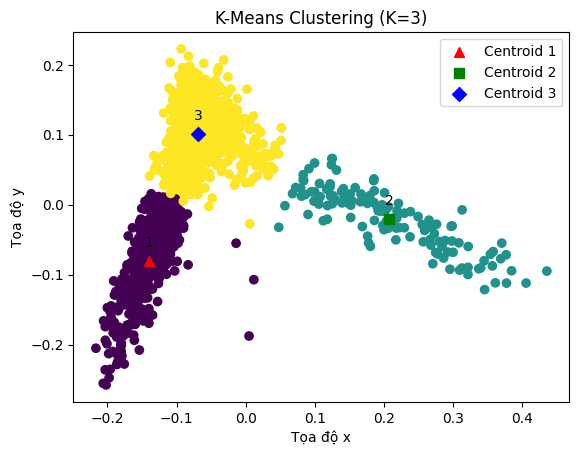

In [48]:
plotting_kmeans(3, tf_idf, centroids, cluster_assignment)

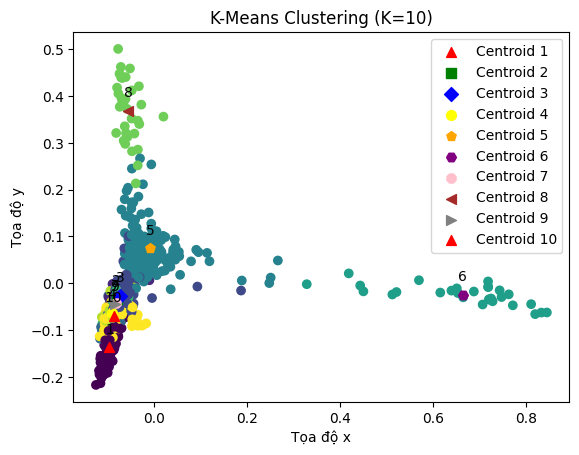

In [49]:
plotting_kmeans(10, tf_idf, centroids, cluster_assignment)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


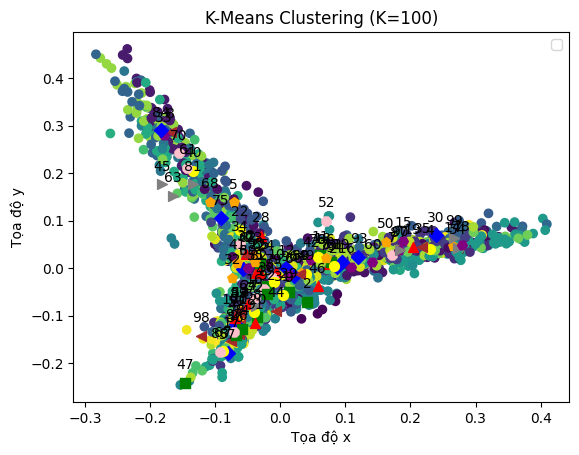

In [27]:
plotting_kmeans(100, tf_idf, centroids, cluster_assignment)

In [22]:
tf_idf, map_index_to_word = sframe_to_scipy_kmean(dataset2, 'tfidf')
tf_idf = normalize(tf_idf)
centroids = {}
cluster_assignment = {}
heterogeneity_values = []
#k_list = [2, 10, 25, 50, 100]
k_list = [3, 10, 100]
seed_list = [0]
#seed_list = [0, 20000, 40000, 60000, 80000, 100000, 120000]
for k in k_list:
    heterogeneity = []
    centroids[k], cluster_assignment[k] = kmeans_multiple_runs(tf_idf, k, maxiter=400,
                                                               num_runs=len(seed_list), seed_list=seed_list,
                                                               verbose=True)
    score = compute_heterogeneity(tf_idf, k, centroids[k], cluster_assignment[k])
    heterogeneity_values.append(score)

seed=000000, heterogeneity=1870.05599
seed=000000, heterogeneity=1793.25158
seed=000000, heterogeneity=1585.60916


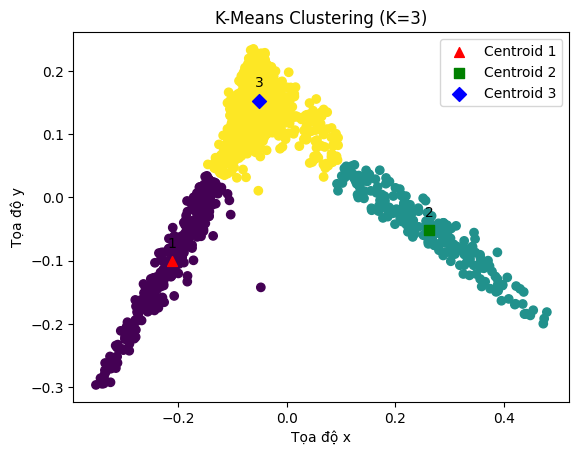

In [51]:
plotting_kmeans(3, tf_idf, centroids, cluster_assignment)

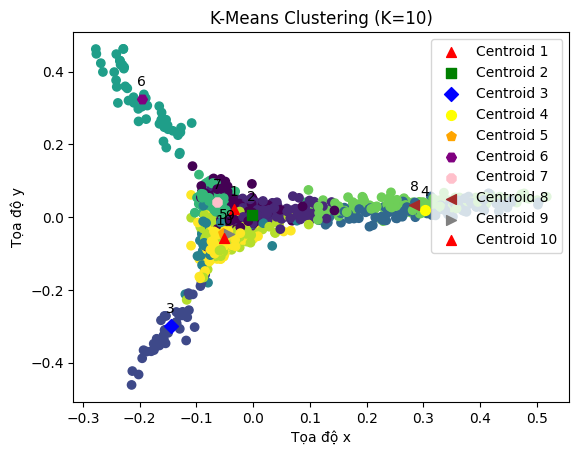

In [52]:
plotting_kmeans(10, tf_idf, centroids, cluster_assignment)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


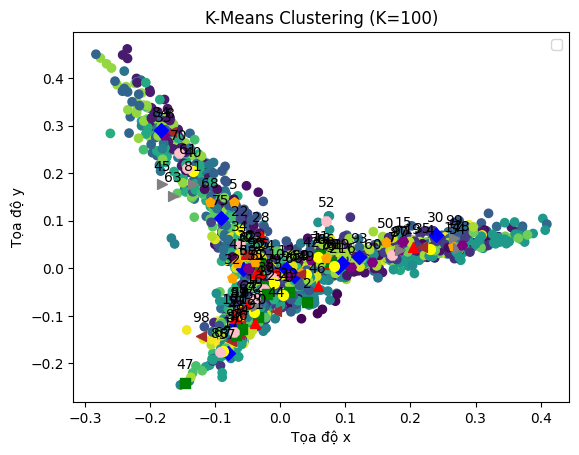

In [28]:
plotting_kmeans(100, tf_idf, centroids, cluster_assignment)

In [56]:
visualize_document_clusters(dataset2, tf_idf, centroids[3], cluster_assignment[3], 3, map_index_to_word, display_content=True)

Cluster 0    
nga:0.135
ukraine:0.116
quân:0.065
khí:0.048
chiến:0.045


* Thế giới                                           0.83583
  Để trả lời các câu hỏi trên, Thanh Niên đã phỏng vấn ông Dov S.Zakheim (cựu Thứ trưởng Bộ 
  Quốc phòng Mỹ và hiện đang

* Thế giới                                           0.83804
  Các cố vấn của Tổng thống Joe Biden đã bắt đầu thảo luận riêng về cách thức và khả năng Tổ
  ng thống Ukraine Volodymyr Zelensky

* Thế giới                                           0.84909
  Trong bản tin cập nhật hoạt động ngày 25.7, Bộ Quốc phòng Nga tuyên bố họ đã đẩy lùi hai t
  àu đổ bộ của Ukraine

* Thế giới                                           0.85085
  "Quân đội Nga đang cố gắng củng cố các vị trí của họ tại các khu vực bị (Nga) kiểm soát ở 
  miền Nam Ukraine,

* Thế giới                                           0.85392
  Giới chức Ukraine ngày 28.6 cho biết 2 tên lửa của Nga đã lao vào một trung tâm mua sắm ở 
  thành phố Kremenchuk, miền

* Thế giới   

In [68]:
def plot_heterogeneity(heterogeneity, k):
    plt.figure(figsize=(7,4))
    plt.plot(heterogeneity, linewidth=4)
    plt.xlabel('# Iterations')
    plt.ylabel('Heterogeneity')
    plt.title('Heterogeneity of clustering over time, K={0:d}'.format(k))
    plt.rcParams.update({'font.size': 16})
    plt.tight_layout()

In [71]:
%%time
import numpy as np 

def plot_k_vs_heterogeneity(k_values, heterogeneity_values):
    plt.figure(figsize=(7,4))
    plt.plot(k_values, heterogeneity_values, linewidth=4)
    plt.xlabel('K')
    plt.ylabel('Heterogeneity')
    plt.title('K vs. Heterogeneity')
    plt.rcParams.update({'font.size': 16})
    plt.tight_layout()


tf_idf, map_index_to_word = sframe_to_scipy_kmean(dataset1, 'tfidf') #term frequency / inverse doc 
tf_idf = normalize(tf_idf)
centroids = {}
cluster_assignment = {}
heterogeneity_values = []
k_list = [3, 10, 25, 50, 100, 200]
seed_list = [0, 20000, 40000, 60000, 80000, 100000, 120000]

for k in k_list:
    heterogeneity = []
    centroids[k], cluster_assignment[k] = kmeans_multiple_runs(tf_idf, k, maxiter=400,
                                                               num_runs=len(seed_list),                                                               seed_list=seed_list,
                                                               verbose=True)
    score = compute_heterogeneity(tf_idf, k, centroids[k], cluster_assignment[k])
    heterogeneity_values.append(score)
    

seed=000000, heterogeneity=1903.62529
seed=020000, heterogeneity=1904.39371
seed=040000, heterogeneity=1903.09180
seed=060000, heterogeneity=1901.70079
seed=080000, heterogeneity=1908.97909
seed=100000, heterogeneity=1906.41214
seed=120000, heterogeneity=1903.42697
seed=000000, heterogeneity=1834.10863
seed=020000, heterogeneity=1842.96667
seed=040000, heterogeneity=1842.03064
seed=060000, heterogeneity=1849.75074
seed=080000, heterogeneity=1847.26617
seed=100000, heterogeneity=1841.25090
seed=120000, heterogeneity=1842.70306
seed=000000, heterogeneity=1771.33131
seed=020000, heterogeneity=1781.53965
seed=040000, heterogeneity=1774.07175
seed=060000, heterogeneity=1766.24577
seed=080000, heterogeneity=1795.38472
seed=100000, heterogeneity=1776.84152
seed=120000, heterogeneity=1771.32902
seed=000000, heterogeneity=1719.08795
seed=020000, heterogeneity=1715.39878
seed=040000, heterogeneity=1716.21098
seed=060000, heterogeneity=1711.80387
seed=080000, heterogeneity=1722.39310
seed=100000,

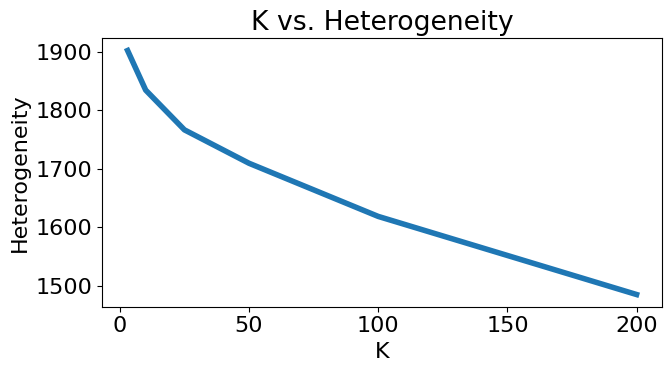

In [72]:
plot_k_vs_heterogeneity(k_list, heterogeneity_values)

0
1
      383 elements changed their cluster assignment.
2
      143 elements changed their cluster assignment.
3
       63 elements changed their cluster assignment.
4
       47 elements changed their cluster assignment.
5
       41 elements changed their cluster assignment.
6
       33 elements changed their cluster assignment.
7
       41 elements changed their cluster assignment.
8
       29 elements changed their cluster assignment.
9
       24 elements changed their cluster assignment.
10
       33 elements changed their cluster assignment.
11
       24 elements changed their cluster assignment.
12
       31 elements changed their cluster assignment.
13
       50 elements changed their cluster assignment.
14
       31 elements changed their cluster assignment.
15
        6 elements changed their cluster assignment.
16
        2 elements changed their cluster assignment.
17
        1 elements changed their cluster assignment.
18
        1 elements changed their cluster assignment.

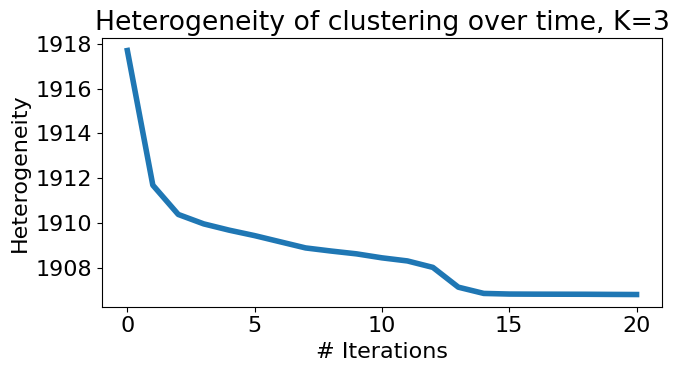

In [76]:
k = 3
heterogeneity = []
initial_centroids = get_initial_centroids(tf_idf, k, seed=0)
centroids, cluster_assignment = kmeans(tf_idf, k, initial_centroids, maxiter=400,
                                       record_heterogeneity=heterogeneity, verbose=True)
plot_heterogeneity(heterogeneity, k)

In [77]:
%%time 
k = 3
heterogeneity_smart = {}
seeds = [0, 20000, 40000, 60000, 80000, 100000, 120000]
for seed in seeds:
    initial_centroids = smart_initialize(tf_idf, k, seed)
    centroids, cluster_assignment = kmeans(tf_idf, k, initial_centroids, maxiter=400,
                                           record_heterogeneity=None, verbose=False)
    heterogeneity_smart[seed] = compute_heterogeneity(tf_idf, k, centroids, cluster_assignment)
    print('seed={0:06d}, heterogeneity={1:.5f}'.format(seed, heterogeneity_smart[seed]))
    sys.stdout.flush()

seed=000000, heterogeneity=1903.62529
seed=020000, heterogeneity=1904.39371
seed=040000, heterogeneity=1903.09180
seed=060000, heterogeneity=1901.70079
seed=080000, heterogeneity=1908.97909
seed=100000, heterogeneity=1906.41214
seed=120000, heterogeneity=1903.42697
CPU times: user 899 ms, sys: 51.7 ms, total: 950 ms
Wall time: 944 ms


In [78]:
k = 3
heterogeneity = {}
cluster_assignment_dict = {}
import time
start = time.time()
for seed in [0, 20000, 40000, 60000, 80000, 100000, 120000]:
    initial_centroids = get_initial_centroids(tf_idf, k, seed)
    centroids, cluster_assignment = kmeans(tf_idf, k, initial_centroids, maxiter=400,
                                           record_heterogeneity=None, verbose=False)
    # To save time, compute heterogeneity only once in the end
    heterogeneity[seed] = compute_heterogeneity(tf_idf, k, centroids, cluster_assignment)
    cluster_assignment_dict[seed] = np.bincount(cluster_assignment)
    print('seed={0:06d}, heterogeneity={1:.5f}, cluster_distribution={2}'.format(seed, heterogeneity[seed], 
                                           cluster_assignment_dict[seed]))
    sys.stdout.flush()
end = time.time()
print(end-start)

seed=000000, heterogeneity=1906.80370, cluster_distribution=[ 622   87 1291]
seed=020000, heterogeneity=1904.61896, cluster_distribution=[1212  651  137]
seed=040000, heterogeneity=1904.21266, cluster_distribution=[ 231  677 1092]
seed=060000, heterogeneity=1903.45590, cluster_distribution=[1201  152  647]
seed=080000, heterogeneity=1905.42509, cluster_distribution=[ 365  261 1374]
seed=100000, heterogeneity=1904.88235, cluster_distribution=[717 654 629]
seed=120000, heterogeneity=1906.46256, cluster_distribution=[1324  300  376]
1.479322910308838


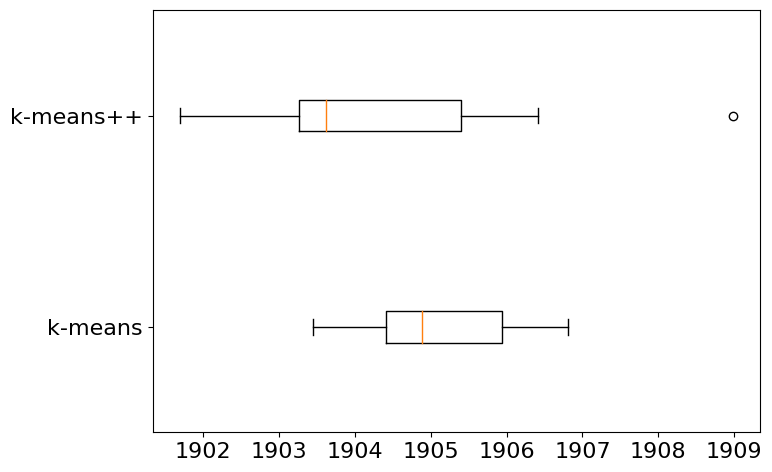

In [79]:
plt.figure(figsize=(8,5))
plt.boxplot([list(heterogeneity.values()), list(heterogeneity_smart.values())], vert=False)
plt.yticks([1, 2], ['k-means', 'k-means++'])
plt.rcParams.update({'font.size': 16})
plt.tight_layout()